# OpsShield — Quantum Incident Response Optimizer

**Hackathon track:** Open-Domain Optimization & Real-World Solvers

This notebook demonstrates OpsShield's infrastructure remediation
optimization model, exact classical baseline, QUBO formulation, and
Qiskit QAOA experiment.

The dataset is synthetic. QAOA is evaluated using local simulation;
this notebook does not claim quantum hardware execution or quantum advantage.


In [7]:
from pathlib import Path
import os
import sys
import pprint

# Locate the OpsShield project root, whether the notebook opens
# from the repository root or the notebooks directory.
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (
    (ROOT / "pyproject.toml").exists()
    and (ROOT / "src" / "opshield").exists()
):
    ROOT = ROOT.parent

if not ((ROOT / "src" / "opshield").exists()):
    raise RuntimeError(
        "Could not locate the OpsShield project root. "
        "Open this notebook from the OpsShield workspace."
    )

os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import qiskit
from opshield.model import (
    ACTIONS,
    exact_classical_solution,
    qubo_coefficients,
    qubo_to_hamiltonian,
)
from opshield.solver import run_qaoa

print("Project root:", ROOT)
print("Qiskit version:", qiskit.__version__)
print("Notebook working directory:", Path.cwd())


Project root: C:\Users\computer\Videos\Quantum Computing\Hackathon\OpsShield-starter\OpsShield
Qiskit version: 2.5.2
Notebook working directory: C:\Users\computer\Videos\Quantum Computing\Hackathon\OpsShield-starter\OpsShield


## 1. Remediation planning problem

OpsShield selects infrastructure remediation actions subject to an
engineering effort budget and incompatibility constraints.

The objective is to maximize total remediation benefit while respecting
the effort budget and avoiding incompatible action pairs.


In [8]:
print("Available remediation actions:")
pprint.pp(ACTIONS)


Available remediation actions:
(RemediationAction(action_id='A1',
                   name='Restore WAN redundancy',
                   effort=3,
                   benefit=10,
                   rationale='Protects connectivity for multiple critical '
                             'sites.'),
 RemediationAction(action_id='A2',
                   name='Correct edge firewall policy',
                   effort=2,
                   benefit=9,
                   rationale='Reduces exposure caused by a known policy error.'),
 RemediationAction(action_id='A3',
                   name='Expand critical storage capacity',
                   effort=2,
                   benefit=8,
                   rationale='Reduces risk of a capacity-related service '
                             'interruption.'),
 RemediationAction(action_id='A4',
                   name='Patch virtualization host',
                   effort=3,
                   benefit=7,
                   rationale='Reduces platform vulner

## 2. Exact classical baseline

An exhaustive search over the 64 possible portfolios of six binary
actions provides a classical reference solution.


In [9]:
baseline = exact_classical_solution()

print("Selected action IDs:", baseline["selected_ids"])
print("Selected actions:", baseline["selected_names"])
print("Total effort:", baseline["effort"], "/ 7")
print("Total benefit:", baseline["benefit"])

assert baseline["effort"] <= 7
assert baseline["benefit"] == 28


Selected action IDs: ['A1', 'A3', 'A5', 'A6']
Selected actions: ['Restore WAN redundancy', 'Expand critical storage capacity', 'Patch externally exposed server', 'Repair monitoring coverage gap']
Total effort: 7 / 7
Total benefit: 28


## 3. QUBO formulation

The binary optimization problem is represented by a Quadratic
Unconstrained Binary Optimization (QUBO) objective. A penalty coefficient
discourages budget violations and incompatible action selections.

The following cell inspects the QUBO coefficients and corresponding
Hamiltonian generated by the project's implementation.


In [10]:
PENALTY = 144

constant, linear, quadratic = qubo_coefficients(penalty=PENALTY)

print("Penalty coefficient:", PENALTY)
print("QUBO constant:", constant)
print("Number of linear coefficients:", len(linear))
print("Linear coefficients:", linear.tolist())
print("Quadratic coefficients:")
pprint.pp(quadratic)

hamiltonian = qubo_to_hamiltonian(penalty=PENALTY)
print("\nHamiltonian type:", type(hamiltonian).__name__)
if hasattr(hamiltonian, "num_qubits"):
    print("Hamiltonian qubits:", hamiltonian.num_qubits)
print(hamiltonian)


Penalty coefficient: 144
QUBO constant: 7056.0
Number of linear coefficients: 9
Linear coefficients: [-4762.0, -3465.0, -3464.0, -4759.0, -1878.0, -1876.0, -1872.0, -3456.0, -5760.0]
Quadratic coefficients:
{(0, 1): 1872.0,
 (0, 2): 1728.0,
 (0, 3): 2592.0,
 (0, 4): 864.0,
 (0, 5): 864.0,
 (0, 6): 864.0,
 (0, 7): 1728.0,
 (0, 8): 3456.0,
 (1, 2): 1152.0,
 (1, 3): 1728.0,
 (1, 4): 576.0,
 (1, 5): 576.0,
 (1, 6): 576.0,
 (1, 7): 1152.0,
 (1, 8): 2304.0,
 (2, 3): 1872.0,
 (2, 4): 576.0,
 (2, 5): 576.0,
 (2, 6): 576.0,
 (2, 7): 1152.0,
 (2, 8): 2304.0,
 (3, 4): 864.0,
 (3, 5): 864.0,
 (3, 6): 864.0,
 (3, 7): 1728.0,
 (3, 8): 3456.0,
 (4, 5): 288.0,
 (4, 6): 288.0,
 (4, 7): 576.0,
 (4, 8): 1152.0,
 (5, 6): 288.0,
 (5, 7): 576.0,
 (5, 8): 1152.0,
 (6, 7): 576.0,
 (6, 8): 1152.0,
 (7, 8): 2304.0}

Hamiltonian type: SparsePauliOp
Hamiltonian qubits: 9
SparsePauliOp(['IIIIIIIII', 'IIIIIIIIZ', 'IIIIIIIZI', 'IIIIIIZII', 'IIIIIZIII', 'IIIIZIIII', 'IIIZIIIII', 'IIZIIIIII', 'IZIIIIIII', 'ZIIIIIIII',

## 4. Execute the QAOA experiment

Run the existing OpsShield solver using Qiskit's QAOA implementation
and local simulation. The parameters below use depth 1, a maximum of
60 optimizer iterations, 4,096 shots and random seed 7.

Generated reports and charts are written to `artifacts/notebook_demo/`.


In [11]:
from IPython.display import display

ARTIFACT_DIR = ROOT / "artifacts" / "notebook_demo"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

qaoa_result = run_qaoa(
    reps=1,
    maxiter=60,
    shots=4096,
    seed=7,
    output_dir=str(ARTIFACT_DIR),
    penalty=PENALTY,
)

print("QAOA result:")
pprint.pp(qaoa_result)


QAOA result:
{'project': 'OpsShield — Quantum Incident Response Optimizer',
 'dataset_note': 'Synthetic demonstration data only; not production incident '
                 'data.',
 'algorithm': 'QAOAAnsatz + StatevectorEstimator + StatevectorSampler',
 'qaoa_reps': 1,
 'qubo_penalty': 144.0,
 'optimizer': 'COBYLA',
 'maxiter': 60,
 'shots': 4096,
 'seed': 7,
 'num_qubits': 9,
 'optimizer_success': True,
 'optimizer_message': 'Return from COBYLA because the trust region radius '
                      'reaches its lower bound.',
 'final_expected_qubo_energy': 1501.7320958200619,
 'objective_evaluations': 22,
 'total_shots': 4096,
 'feasible_shots': 464,
 'feasibility_yield': 0.11328125,
 'exact_classical_optimum': {'bits': [1, 0, 1, 0, 1, 1],
                             'selected_ids': ['A1', 'A3', 'A5', 'A6'],
                             'selected_names': ['Restore WAN redundancy',
                                                'Expand critical storage '
                            

## 5. Inspect generated reports and plots

The next cell displays generated JSON reports and PNG charts, if present,
so the saved notebook can retain visible evidence of the experiment.


Artifact directory: C:\Users\computer\Videos\Quantum Computing\Hackathon\OpsShield-starter\OpsShield\artifacts\notebook_demo
Generated file count: 3

File: artifacts\notebook_demo\qaoa_energy.png


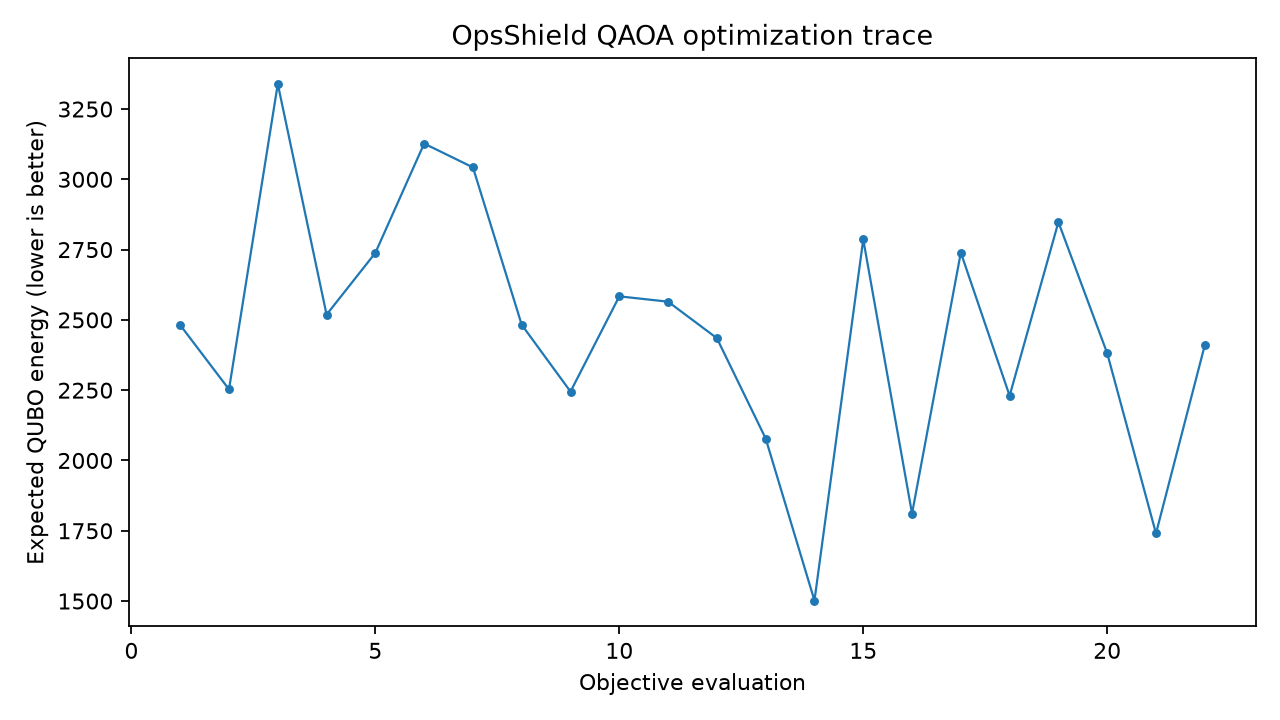


File: artifacts\notebook_demo\results.json
{
  "project": "OpsShield \u2014 Quantum Incident Response Optimizer",
  "dataset_note": "Synthetic demonstration data only; not production incident data.",
  "algorithm": "QAOAAnsatz + StatevectorEstimator + StatevectorSampler",
  "qaoa_reps": 1,
  "qubo_penalty": 144.0,
  "optimizer": "COBYLA",
  "maxiter": 60,
  "shots": 4096,
  "seed": 7,
  "num_qubits": 9,
  "optimizer_success": true,
  "optimizer_message": "Return from COBYLA because the trust region radius reaches its lower bound.",
  "final_expected_qubo_energy": 1501.7320958200619,
  "objective_evaluations": 22,
  "total_shots": 4096,
  "feasible_shots": 464,
  "feasibility_yield": 0.11328125,
  "exact_classical_optimum": {
    "bits": [
      1,
      0,
      1,
      0,
      1,
      1
    ],
    "selected_ids": [
      "A1",
      "A3",
      "A5",
      "A6"
    ],
    "selected_names": [
      "Restore WAN redundancy",
      "Expand critical storage capacity",
      "Patch ext

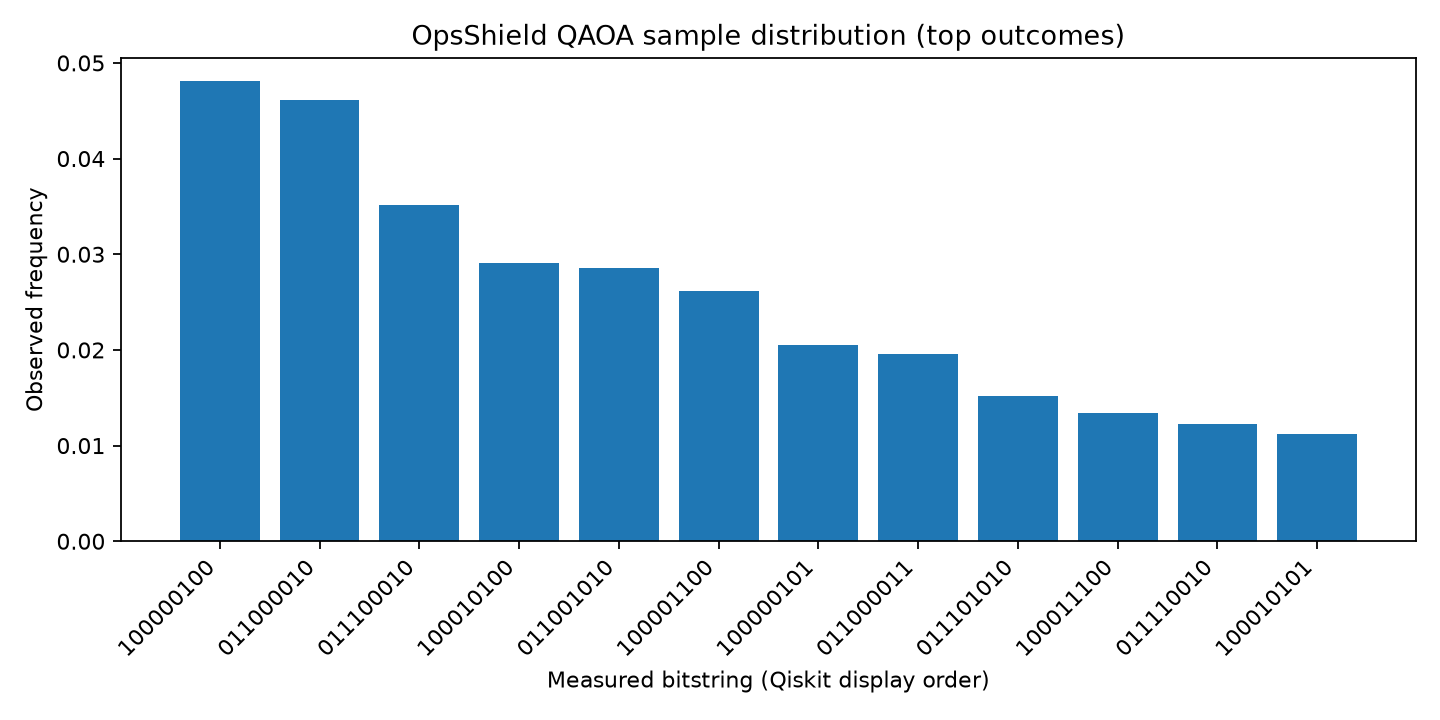

In [12]:
import json
from IPython.display import Image, Markdown, display

generated_files = sorted(
    p for p in ARTIFACT_DIR.rglob("*") if p.is_file()
)

print("Artifact directory:", ARTIFACT_DIR)
print("Generated file count:", len(generated_files))

for file in generated_files:
    print("\nFile:", file.relative_to(ROOT))

    if file.suffix.lower() == ".png":
        display(Image(filename=str(file)))
    elif file.suffix.lower() == ".json":
        try:
            with file.open(encoding="utf-8") as stream:
                report = json.load(stream)
            print(json.dumps(report, indent=2, default=str))
        except (ValueError, OSError) as exc:
            print("Could not display JSON report:", exc)
    elif file.suffix.lower() == ".csv":
        print(file.read_text(encoding="utf-8")[:12000])

if not generated_files:
    print("No files were generated in the artifact directory.")


## 6. Interpretation and limitations

- The exact classical baseline provides a reference for evaluating QAOA.
- QAOA performance depends on parameters, sampling and random seed.
- Synthetic inputs do not establish real-world operational performance.
- Local simulation does not demonstrate execution on quantum hardware.
- No quantum advantage is claimed.

For reproducibility, this notebook records the parameters used for the
QAOA experiment and retains cell outputs after execution.
